# SignSense — First look at train.csv

Exploration only: no data is modified.

This notebook examines dataset size, data quality, and the distribution of signs and participants before preprocessing.

In [38]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


In [39]:



TRAIN_CSV = Path(r"E:\SignSense_data\raw\train.csv")

df = pd.read_csv(TRAIN_CSV)
df.head()

,path,participant_id,sequence_id,sign
0,train_landmark_files/26734/1000035562.parquet,26734,1000035562,blow
1,train_landmark_files/28656/1000106739.parquet,28656,1000106739,wait
2,train_landmark_files/16069/100015657.parquet,16069,100015657,cloud
3,train_landmark_files/25571/1000210073.parquet,25571,1000210073,bird
4,train_landmark_files/62590/1000240708.parquet,62590,1000240708,owie


In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94477 entries, 0 to 94476
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   path            94477 non-null  object
 1   participant_id  94477 non-null  int64 
 2   sequence_id     94477 non-null  int64 
 3   sign            94477 non-null  object
dtypes: int64(2), object(2)
memory usage: 2.9+ MB


In [41]:
df.duplicated().sum()

0

In [42]:
print("Shape (rows, columns):", df.shape)
print("Missing values (all columns):", int(df.isna().sum().sum()))
print("Duplicated sequence_id:", int(df["sequence_id"].duplicated().sum()))
print("Number of signs:", df["sign"].nunique())
print("Number of participants:", df["participant_id"].nunique())

Shape (rows, columns): (94477, 4)
Missing values (all columns): 0
Duplicated sequence_id: 0
Number of signs: 250
Number of participants: 21


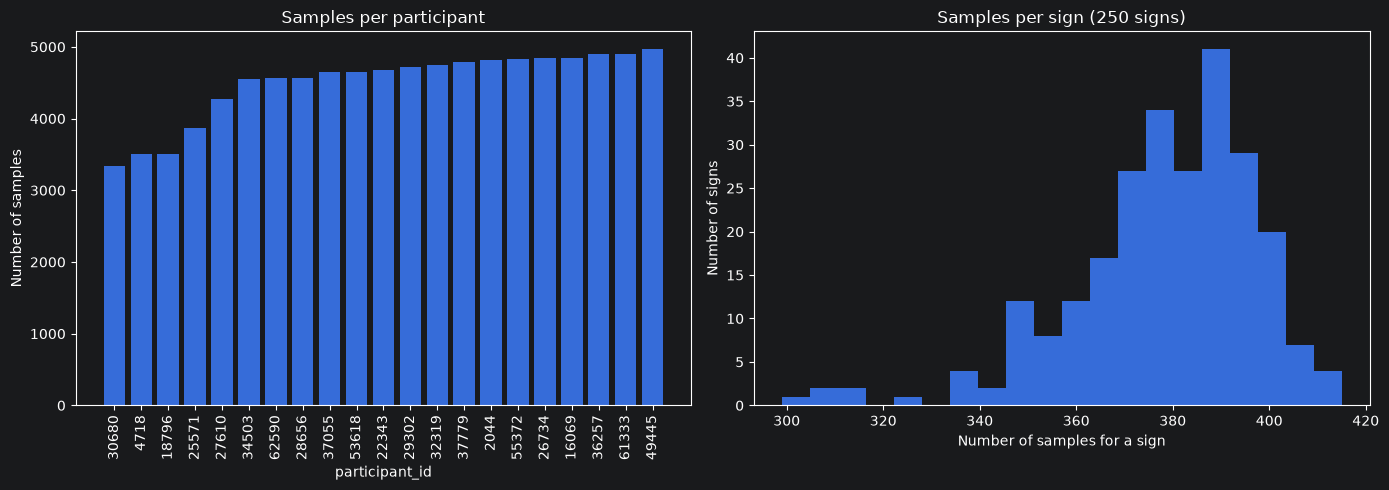

In [43]:


per_participant = df["participant_id"].value_counts().sort_values()
per_sign = df["sign"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: samples per participant (one bar per person)
axes[0].bar(per_participant.index.astype(str), per_participant.values)
axes[0].set_title("Samples per participant")
axes[0].set_xlabel("participant_id")
axes[0].set_ylabel("Number of samples")
axes[0].tick_params(axis="x", rotation=90)

# Right: how many signs have each sample count
axes[1].hist(per_sign.values, bins=20)
axes[1].set_title("Samples per sign (250 signs)")
axes[1].set_xlabel("Number of samples for a sign")
axes[1].set_ylabel("Number of signs")

plt.tight_layout()
plt.show()

In [44]:

sign_counts = df["sign"].value_counts()

print("Most frequent signs:")
display(sign_counts.head(10))

print("\nLeast frequent signs:")
display(sign_counts.tail(10))





Most frequent signs:


sign
listen     415
look       414
shhh       411
donkey     410
mouse      408
duck       405
hear       405
uncle      405
pretend    404
bird       404
Name: count, dtype: int64


Least frequent signs:


sign
have      337
table     337
jacket    336
night     336
down      327
dance     312
person    312
beside    310
vacuum    307
zipper    299
Name: count, dtype: int64

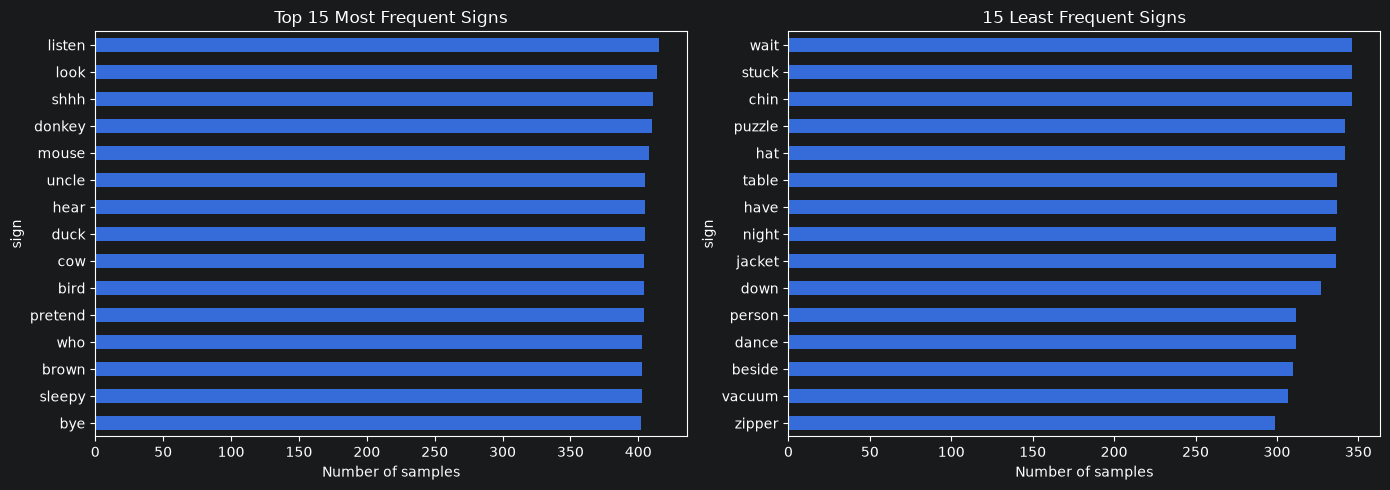

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sign_counts.head(15).sort_values().plot(
    kind="barh", ax=axes[0]
)
axes[0].set_title("Top 15 Most Frequent Signs")
axes[0].set_xlabel("Number of samples")

sign_counts.tail(15).sort_values().plot(
    kind="barh", ax=axes[1]
)
axes[1].set_title("15 Least Frequent Signs")
axes[1].set_xlabel("Number of samples")

plt.tight_layout()
plt.show()